In [12]:
import pandas as pd
import matplotlib.ticker as mticker # Needed for y-axis formatting
import matplotlib.pyplot as plt
import numpy as np

In [9]:
df = pd.read_csv('/Users/go202/Desktop/EQUATE/huggingface_longitudinal_work/wayback_work/huggingface_languages_timeseries.csv')

/var/folders/hw/3z11r39j0gd4kgzxbjj6v8z80000gp/T/ipykernel_99783/2588941549.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  a.legend(loc='upper left')


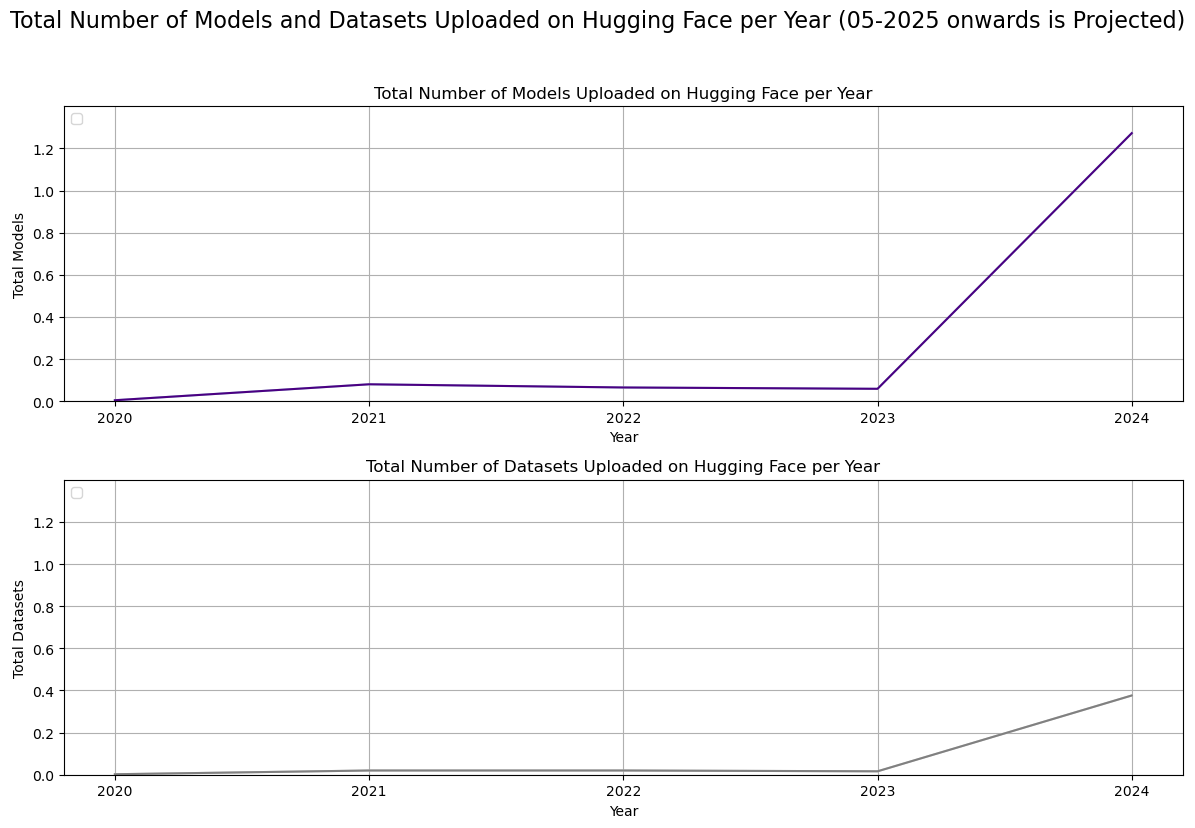

In [14]:
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year

# Step 1: Get latest snapshot per year
latest_dates = df.groupby("year")["date"].max().reset_index()
latest_snapshots = pd.merge(df, latest_dates, on=["year", "date"])

# Step 2: Sum for years before 2025
yearly_totals = latest_snapshots.groupby("year")[["models", "datasets"]].sum().reset_index()
yearly_totals = yearly_totals[yearly_totals["year"] < 2025]

# Initialize extra columns to 0 for existing years before concatenating
yearly_totals["extra_models"] = 0
yearly_totals["extra_datasets"] = 0
yearly_totals = pd.concat([yearly_totals], ignore_index=True)
yearly_totals = yearly_totals[yearly_totals["year"] < 2025] 

# Removed sharex=True to allow independent x-axis labels
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Models
# Plotting projected line (actual + extra)
ax[0].plot(yearly_totals["year"], yearly_totals["models"],color="lightblue")
# Filling between actual and projected

# Plotting actual line
ax[0].plot(yearly_totals["year"], yearly_totals["models"], color="indigo")
ax[0].set_ylabel("Total Models")
ax[0].set_title("Total Number of Models Uploaded on Hugging Face per Year")
ax[0].set_xlabel("Year")

# Datasets
# Plotting projected line (actual + extra)
ax[1].plot(yearly_totals["year"], yearly_totals["datasets"], color="lightgray")
# Filling between actual and projected
# Plotting actual line
ax[1].plot(yearly_totals["year"], yearly_totals["datasets"], color="gray")
ax[1].set_ylabel("Total Datasets")
ax[1].set_title("Total Number of Datasets Uploaded on Hugging Face per Year")
ax[1].set_xlabel("Year")


# Determine global max for y-axis consistency
max_models = (yearly_totals["models"]).max()
max_datasets = (yearly_totals["datasets"]).max()
global_max_y = max(max_models, max_datasets) * 1.1

# Common settings
for a in ax:
    a.legend(loc='upper left')
    a.grid(True)
    a.set_ylim(0, global_max_y)

    # Format y-axis to display in 1e6 format
    formatter = mticker.FormatStrFormatter('%.1f') # Displays 1.0, 1.2, etc.
    a.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x/1e6:.1f}' if x != 0 else '0.0')) # Divide by 1e6
    a.set_yticks(np.arange(0, global_max_y, global_max_y / 7)) # Adjust tick density if needed

    # Set x-axis tick formatter to display integers without .0
    x_formatter = mticker.FormatStrFormatter('%d')
    a.xaxis.set_major_formatter(x_formatter)
    a.xaxis.set_major_locator(mticker.FixedLocator(yearly_totals["year"].unique()))


fig.suptitle("Total Number of Models and Datasets Uploaded on Hugging Face per Year (05-2025 onwards is Projected)", fontsize=16, y=1.03)

plt.tight_layout()
plt.savefig("develop_over_time_no_proj.pdf")
plt.show()

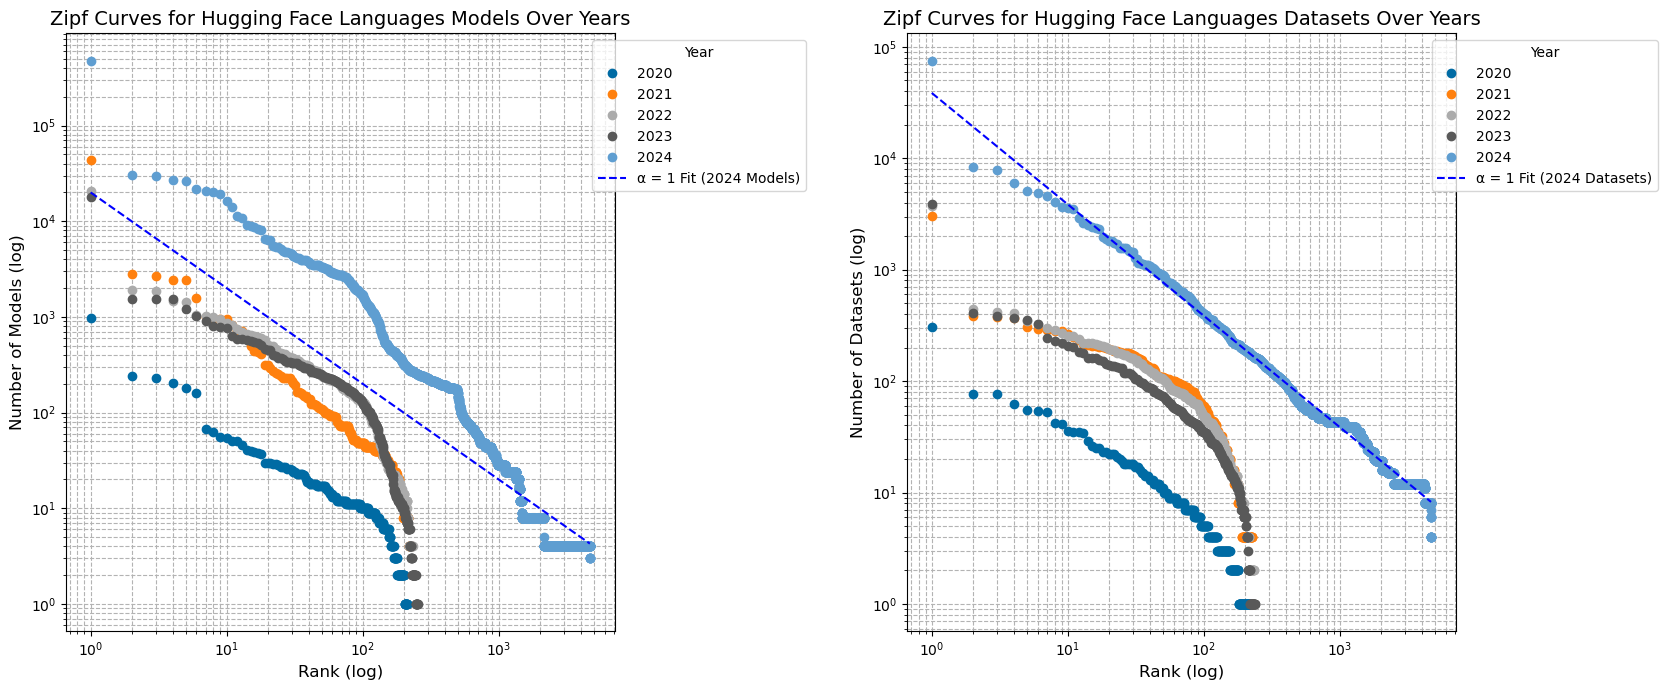

In [17]:
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year

# Step 1: Get latest snapshot date per year
latest_dates = df.groupby("year")["date"].max().reset_index()

# Step 2: Merge to get all rows from latest snapshot of each year
latest_snapshots = pd.merge(df, latest_dates, on=["year", "date"])

# Step 3: Remove 2025 as it's not a complete year
latest_snapshots = latest_snapshots[latest_snapshots["year"] < 2025]

# Step 4: Apply a colorblind-friendly style and prepare the figure with two subplots
plt.style.use('tableau-colorblind10')
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=False) # Two columns, wider figure

# Removed the explicit year_colors dictionary, Matplotlib will use the style's default cycle

# --- Plot 1: Models ---
ax1 = axes[0] # First subplot for Models
for year in sorted(latest_snapshots["year"].unique()):
    data = latest_snapshots[latest_snapshots["year"] == year]
    lang_model_counts = data.groupby("code")["models"].sum().sort_values(ascending=False)

    ranks = np.arange(1, len(lang_model_counts) + 1)
    frequencies = lang_model_counts.values

    valid_indices = (frequencies > 0) & (ranks > 0)
    ranks_filtered = ranks[valid_indices]
    frequencies_filtered = frequencies[valid_indices]

    # Removed the 'color' parameter to use default style colors
    ax1.plot(ranks_filtered, frequencies_filtered, marker='o', linestyle='',
             label=f"{year}")

    # Add the Alpha = 1 Line specifically for the 2024 data (Models)
    if year == 2024 and len(ranks_filtered) >= 2:
        log_ranks_for_fit = np.log(ranks_filtered)
        log_frequencies_for_fit = np.log(frequencies_filtered)

        m_alpha1 = -1.0
        c_alpha1 = np.mean(log_frequencies_for_fit - m_alpha1 * log_ranks_for_fit)

        fit_ranks_range = np.array([ranks_filtered.min(), ranks_filtered.max()])
        fit_log_ranks_range = np.log(fit_ranks_range)
        fit_frequencies_alpha1 = np.exp(m_alpha1 * fit_log_ranks_range + c_alpha1)

        ax1.plot(fit_ranks_range, fit_frequencies_alpha1, color='blue', linestyle='--', linewidth=1.5,
                 label=f"α = 1 Fit (2024 Models)")

ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_title("Zipf Curves for Hugging Face Languages Models Over Years", fontsize=14)
ax1.set_xlabel("Rank (log)", fontsize=12)
ax1.set_ylabel("Number of Models (log)", fontsize=12) # Adjusted label back to "Models (log)"
ax1.legend(title="Year", loc='upper right', bbox_to_anchor=(1.36, 1)) # Moved legend outside for clarity
ax1.grid(True, which="both", ls="--", c='0.7')

# --- Plot 2: Datasets ---
ax2 = axes[1] # Second subplot for Datasets
for year in sorted(latest_snapshots["year"].unique()):
    data = latest_snapshots[latest_snapshots["year"] == year]
    lang_dataset_counts = data.groupby("code")["datasets"].sum().sort_values(ascending=False)

    ranks = np.arange(1, len(lang_dataset_counts) + 1)
    frequencies = lang_dataset_counts.values

    valid_indices = (frequencies > 0) & (ranks > 0)
    ranks_filtered = ranks[valid_indices]
    frequencies_filtered = frequencies[valid_indices]

    # Removed the 'color' parameter to use default style colors
    ax2.plot(ranks_filtered, frequencies_filtered, marker='o', linestyle='',
             label=f"{year}")

    # Add the Alpha = 1 Line specifically for the 2024 data (Datasets)
    if year == 2024 and len(ranks_filtered) >= 2:
        log_ranks_for_fit = np.log(ranks_filtered)
        log_frequencies_for_fit = np.log(frequencies_filtered)

        m_alpha1 = -1.0
        c_alpha1 = np.mean(log_frequencies_for_fit - m_alpha1 * log_ranks_for_fit)

        fit_ranks_range = np.array([ranks_filtered.min(), ranks_filtered.max()])
        fit_log_ranks_range = np.log(fit_ranks_range)
        fit_frequencies_alpha1 = np.exp(m_alpha1 * fit_log_ranks_range + c_alpha1)

        ax2.plot(fit_ranks_range, fit_frequencies_alpha1, color='blue', linestyle='--', linewidth=1.5,
                 label=f"α = 1 Fit (2024 Datasets)")

ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_title("Zipf Curves for Hugging Face Languages Datasets Over Years", fontsize=14)
ax2.set_xlabel("Rank (log)", fontsize=12)
ax2.set_ylabel("Number of Datasets (log)", fontsize=12)
ax2.legend(title="Year", loc='upper right', bbox_to_anchor=(1.38, 1)) # Moved legend outside for clarity
ax2.grid(True, which="both", ls="--", c='0.7')

plt.tight_layout(rect=[0, 0, 0.95, 1]) # Adjust layout to make space for the legends
plt.savefig('combined_zipfs_models_datasets_original_colors.pdf') # New filename
plt.show()